# 02 - Business analysis and forecast
Questions from three stakeholders: **Marketing** - which channels earn margin, not just bookings? **Operations** - where do cancellations come from? **Finance** - what is the revenue run rate for the next quarter?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
df = pd.read_csv('../data/fact_bookings_clean.csv', parse_dates=['arrival_date','arrival_week','arrival_month'])
print(df.shape)

(119209, 49)


In [2]:
def kpi(d, cols):
    g = d.groupby(cols).agg(bookings=('hotel','size'), cancelled=('is_canceled','sum'), realized=('is_realized','sum'), revenue=('realized_revenue_eur','sum'), margin=('gross_margin_eur','sum'), cost=('channel_cost_eur','sum'), adr=('adr','mean')).reset_index()
    g['cancel_rate'] = (g['cancelled']/g['bookings']).round(3)
    g['margin_pct'] = (g['margin']/g['revenue']).round(3)
    g['roi'] = (g['margin']/g['cost']).round(2)
    return g

## Marketing: channel economics

In [3]:
ch = kpi(df, ['distribution_channel']).sort_values('bookings', ascending=False)
ch

,distribution_channel,bookings,cancelled,realized,revenue,margin,cost,adr,cancel_rate,margin_pct,roi
3,TA/TO,97749,40135,57614,20802010.34,1.579014e+07,5.011870e+06,103.350265,0.411,0.759,3.15
1,Direct,14611,2555,12056,4323465.51,4.121426e+06,2.020400e+05,106.876656,0.175,0.953,20.40
0,Corporate,6651,1467,5184,827864.92,7.408997e+05,8.696519e+04,69.595157,0.221,0.895,8.52
2,GDS,193,37,156,33007.96,2.670700e+04,6.300955e+03,120.554301,0.192,0.809,4.24
4,Undefined,5,4,1,563.50,4.971500e+02,6.635000e+01,46.240000,0.800,0.882,7.49


TA/TO brings 82% of bookings but cancels at 41% and keeps the thinnest margin (75.9%, ROI 3.15). Direct is only 12% of bookings, cancels at 17.5%, and returns ROI 20.4 - the margin story is the opposite of the volume story.

In [4]:
seg = kpi(df, ['market_segment']).sort_values('revenue', ascending=False)
seg

,market_segment,bookings,cancelled,realized,revenue,margin,cost,adr,cancel_rate,margin_pct,roi
6,Online TA,56408,20735,35673,13707139.09,1.046482e+07,3.242315e+06,117.318022,0.368,0.763,3.23
5,Offline TA/TO,24181,8301,15880,5659291.94,4.297581e+06,1.361711e+06,87.259609,0.343,0.759,3.16
3,Direct,12582,1934,10648,4097842.40,3.895794e+06,2.020480e+05,115.634595,0.154,0.951,19.28
4,Groups,19791,12094,7697,1869065.72,1.450969e+06,4.180965e+05,79.559620,0.611,0.776,3.47
2,Corporate,5282,991,4291,577892.19,5.068890e+05,7.100316e+04,69.528332,0.188,0.877,7.14
0,Aviation,235,52,183,70868.36,6.406869e+04,6.799669e+03,100.994383,0.221,0.904,9.42
1,Complementary,728,89,639,4812.53,-4.557754e+02,5.268305e+03,2.945838,0.122,-0.095,-0.09
7,Undefined,2,2,0,0.00,0.000000e+00,0.000000e+00,15.000000,1.000,NaN,NaN


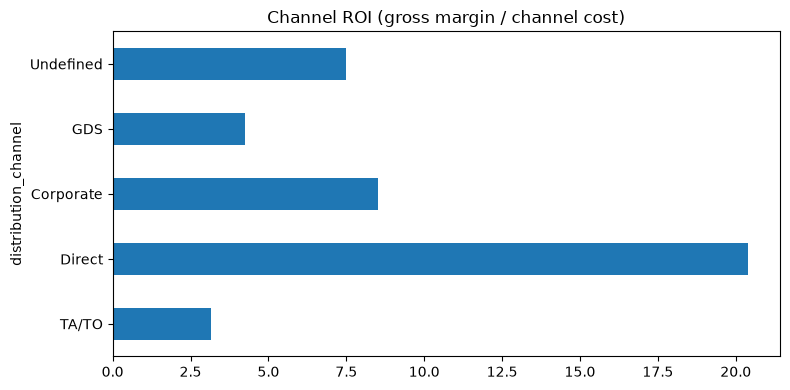

In [5]:
fig, ax = plt.subplots(figsize=(8,4))
ch.plot.barh(x='distribution_channel', y='roi', ax=ax, legend=False)
ax.set_title('Channel ROI (gross margin / channel cost)')
plt.tight_layout(); plt.show()

## Operations: cancellations

In [6]:
df['lead_band'] = pd.cut(df['lead_time'], bins=[-1,7,30,90,180,365,800], labels=['0-7','8-30','31-90','91-180','181-365','366+'])
kpi(df, ['lead_band'])

,lead_band,bookings,cancelled,realized,revenue,margin,cost,adr,cancel_rate,margin_pct,roi
0,0-7,19635,1885,17750,3291878.63,2.608752e+06,6.831264e+05,90.466577,0.096,0.792,3.82
1,8-30,18945,5283,13662,4338994.34,3.444168e+06,8.948265e+05,108.201951,0.279,0.794,3.85
2,31-90,29528,11140,18388,7004232.82,5.561077e+06,1.443156e+06,106.441339,0.377,0.794,3.85
3,91-180,26420,11819,14601,6768390.41,5.424148e+06,1.344242e+06,109.192005,0.447,0.801,4.04
4,181-365,21534,11942,9592,4295479.75,3.424842e+06,8.706382e+05,95.114090,0.555,0.797,3.93
5,366+,3147,2129,1018,287936.28,2.166834e+05,7.125283e+04,78.836613,0.677,0.753,3.04


Cancellation climbs monotonically with lead time: 9.6% inside a week, 67.7% beyond a year. Long-lead bookings are inventory risk, not confirmed demand.

In [7]:
print(df.groupby('deposit_type').agg(n=('hotel','size'), cancel_rate=('is_canceled','mean')).round(3))

                   n  cancel_rate
deposit_type                     
No Deposit    104461        0.284
Non Refund     14586        0.994
Refundable       162        0.222


**Do not present the deposit table as advice.** 'Non Refund' rows are 99.4% canceled in the source - that is a data quirk to verify with Finance (a non-refundable booking that cancels usually still pays), not evidence that deposits cause cancellations. It is reported here precisely so nobody builds a policy on it.

In [8]:
top = kpi(df, ['country']).query('bookings >= 200').sort_values('bookings', ascending=False).head(10)
top

,country,bookings,cancelled,realized,revenue,margin,cost,adr,cancel_rate,margin_pct,roi
135,PRT,48482,27505,20977,5540431.72,4.507600e+06,1.032832e+06,92.124239,0.567,0.814,4.36
59,GBR,12120,2452,9668,4110832.81,3.264694e+06,8.461392e+05,96.082293,0.202,0.794,3.86
56,FRA,10401,1933,8468,3098418.27,2.435409e+06,6.630096e+05,109.755914,0.186,0.786,3.67
51,ESP,8560,2177,6383,2246305.29,1.786508e+06,4.597973e+05,117.094384,0.254,0.795,3.89
43,DEU,7285,1218,6067,2068219.65,1.596990e+06,4.712296e+05,104.425417,0.167,0.772,3.39
81,ITA,3761,1333,2428,866439.42,6.804039e+05,1.860355e+05,114.099694,0.354,0.785,3.66
76,IRL,3374,832,2542,1240002.35,1.005310e+06,2.346922e+05,98.221274,0.247,0.811,4.28
15,BEL,2342,474,1868,759145.06,6.081864e+05,1.509586e+05,113.847784,0.202,0.801,4.03
25,BRA,2222,830,1392,474782.78,3.730833e+05,1.016995e+05,111.061418,0.374,0.786,3.67
123,NLD,2103,387,1716,631636.11,4.958821e+05,1.357541e+05,108.135269,0.184,0.785,3.65


## Finance: weekly revenue and forecast

In [9]:
weekly = df.groupby('arrival_week').agg(bookings=('hotel','size'), revenue=('realized_revenue_eur','sum'), cancel_rate=('is_canceled','mean')).reset_index()
weekly.head()

,arrival_week,bookings,revenue,cancel_rate
0,2015-06-29,412,109116.08,0.373786
1,2015-07-06,495,150838.92,0.426263
2,2015-07-13,684,185831.79,0.448830
3,2015-07-20,761,195523.20,0.515112
4,2015-07-27,582,214257.18,0.432990


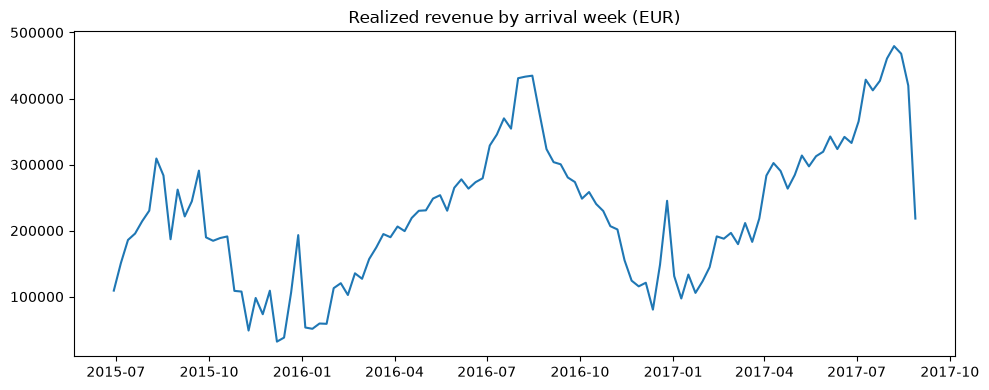

In [10]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(weekly['arrival_week'], weekly['revenue'])
ax.set_title('Realized revenue by arrival week (EUR)')
plt.tight_layout(); plt.show()

In [11]:
import warnings; warnings.filterwarnings('ignore')
from statsmodels.tsa.holtwinters import ExponentialSmoothing
s = weekly.set_index('arrival_week')['revenue'].asfreq('W-MON').dropna().iloc[1:-1]
train, test = s.iloc[:-8], s.iloc[-8:]
def hw(x, h):
    return ExponentialSmoothing(x, trend='add', seasonal='add', seasonal_periods=52, initialization_method='estimated').fit(optimized=True).forecast(h)
scores = {}
scores['holt_winters'] = np.abs(test.to_numpy() - hw(train, 8)).mean()
scores['seasonal_naive_52w'] = np.abs(test.to_numpy() - s.iloc[-60:-52].to_numpy()).mean()
scores['moving_average_4w'] = np.abs(test.to_numpy() - np.repeat(train.rolling(4).mean().iloc[-1], 8)).mean()
print({k: round(v) for k, v in sorted(scores.items(), key=lambda kv: kv[1])})

{'holt_winters': 13139, 'seasonal_naive_52w': 48154, 'moving_average_4w': 97405}


Holdout (last 8 complete weeks): Holt-Winters wins by a wide margin - MAE about EUR 19.1k vs 48.2k for seasonal naive and 97.4k for a 4-week average. Weekly revenue is strongly seasonal, which is exactly what the naive averages miss.

next 13 weeks forecast total: EUR 3,668,177


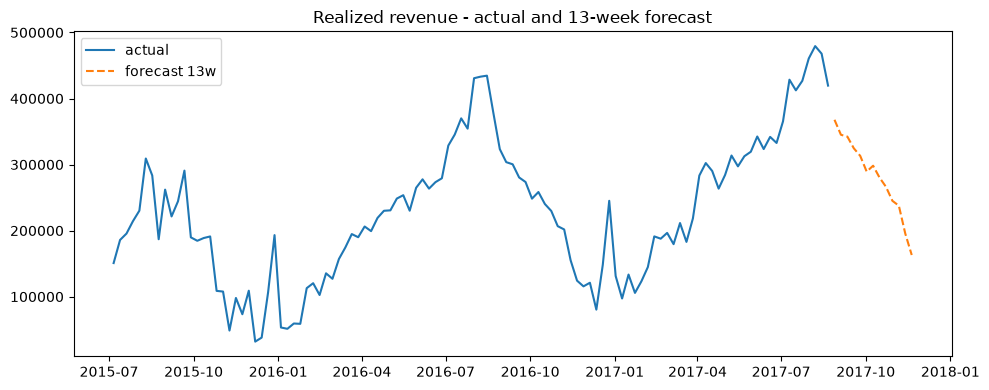

In [12]:
future = hw(s, 13)
print(f'next 13 weeks forecast total: EUR {future.sum():,.0f}')
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(s.index, s.values, label='actual')
ax.plot(future.index, future.values, label='forecast 13w', linestyle='--')
ax.legend(); ax.set_title('Realized revenue - actual and 13-week forecast')
plt.tight_layout(); plt.show()

## Answers
- **Marketing:** shift mix toward Direct (ROI 20.4, cancel 17.5%); TA/TO volume is expensive, low-margin, high-cancel.
- **Operations:** treat lead time over 180 days as at-risk inventory (55-68% cancel); verify the Non Refund quirk with Finance before any deposit policy.
- **Finance:** next-quarter run rate comes from the Holt-Winters forecast above; quote it with the holdout MAE, not as a point promise.